# Tasks for laboratory assignment 3

In [5]:
# imports section

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures

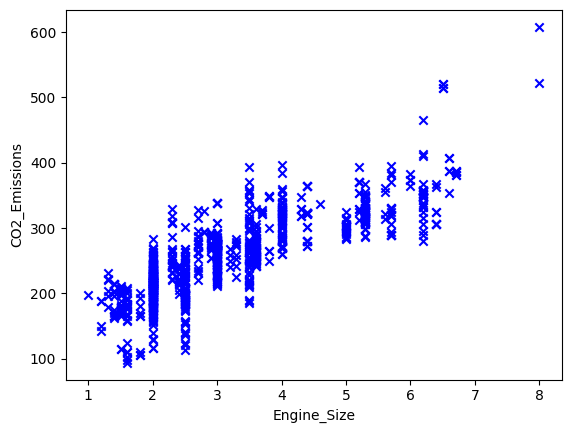

In [6]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [7]:
import os
import pandas as pd

def extract_texts_from_file(file_path):
    """
    Extract data from the csv file.

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        pd.DataFrame: The loaded dataset.
    """
    if os.path.exists(file_path):
        return pd.read_csv(file_path)
    else:
        github_raw_url = f"https://raw.githubusercontent.com/Mariia-Mytsak/ida-labs/main/{file_path}"
        return pd.read_csv(github_raw_url)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

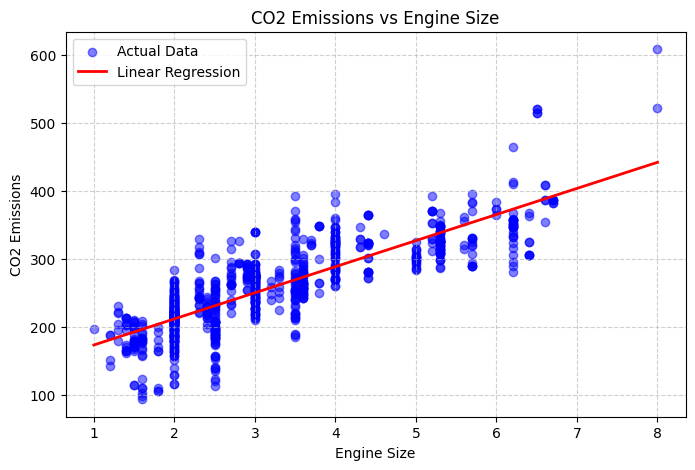

Theta parameters: [135.3260546026322, 38.32301106042745]


[135.3260546026322, 38.32301106042745]

In [8]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters [intercept, slope].
    """
    # Видаляємо пропуски, якщо вони є
    df = data[['Engine_Size', 'CO2_Emissions']].dropna()

    X = df[['Engine_Size']].values
    y = df['CO2_Emissions'].values

    model = LinearRegression()
    model.fit(X, y)

    # Візуалізація
    plt.figure(figsize=(8, 5))
    plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')

    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    plt.plot(X_range, model.predict(X_range), color='red', linewidth=2, label='Linear Regression')

    plt.title('CO2 Emissions vs Engine Size')
    plt.xlabel('Engine Size')
    plt.ylabel('CO2 Emissions')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    # Параметри theta: [theta_0 (intercept), theta_1 (coef)]
    theta = [float(model.intercept_)] + [float(c) for c in model.coef_]
    print("Theta parameters:", theta)
    return theta

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

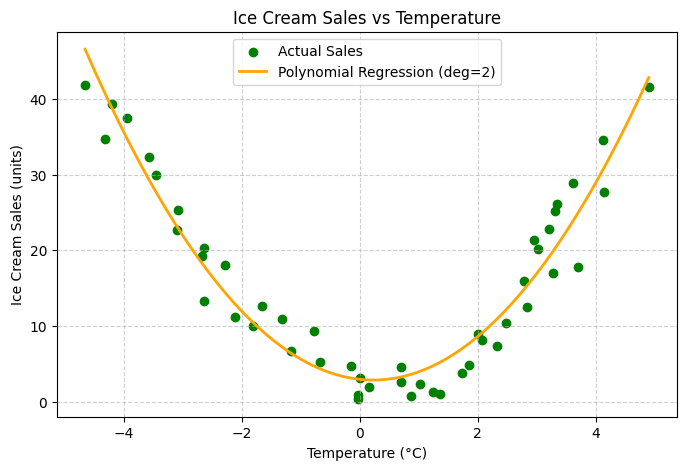

Theta parameters: [2.9517741579934498, -0.8246816702106483, 1.829526229670208]


[2.9517741579934498, -0.8246816702106483, 1.829526229670208]

In [9]:
def ice_cream_selling(data):
    """
    Build a model that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    # Беремо першу колонку як температуру (X), другу як продажі (y)
    df = data.dropna()
    x_col, y_col = df.columns[0], df.columns[1]

    X = df[[x_col]].values
    y = df[y_col].values

    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    # Візуалізація
    plt.figure(figsize=(8, 5))
    plt.scatter(X, y, color='green', label='Actual Sales')

    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_pred = model.predict(poly.transform(X_range))
    plt.plot(X_range, y_pred, color='orange', linewidth=2, label='Polynomial Regression (deg=2)')

    plt.title('Ice Cream Sales vs Temperature')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    theta = [float(model.intercept_)] + [float(c) for c in model.coef_[1:]]
    print("Theta parameters:", theta)
    return theta

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

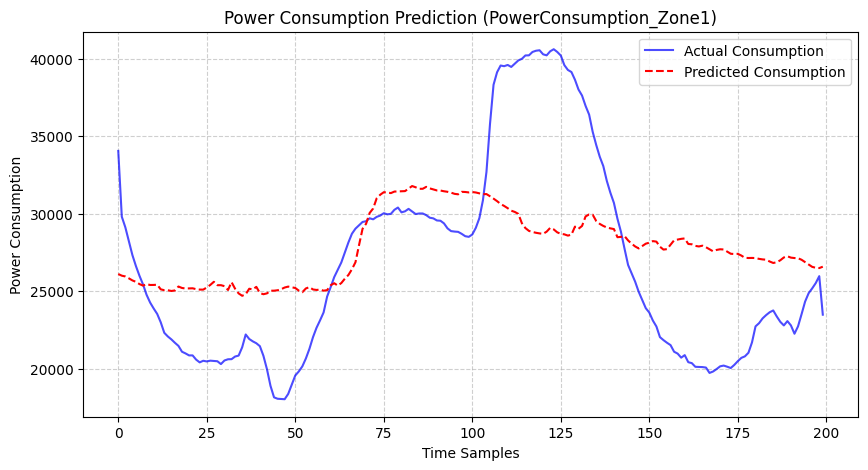

Theta parameters: [26283.803478197293, 507.4126885995117, -47.19708160521377, -133.5183312218982]


[26283.803478197293, 507.4126885995117, -47.19708160521377, -133.5183312218982]

In [10]:
def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed.
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    df = data.dropna()

    # Визначаємо колонки погодних умов та цільову колонку споживання
    features = ['Temperature', 'Humidity', 'WindSpeed']
    # Якщо назви колонок у файлі трохи відрізняються (наприклад, з пробілами), підбираємо автоматично:
    available_cols = df.columns.tolist()
    X_cols = [c for c in available_cols if any(k in c.lower() for k in ['temp', 'humid', 'wind'])][:3]
    y_col = [c for c in available_cols if 'power' in c.lower() or 'consumption' in c.lower() or 'zone' in c.lower()][0]

    X = df[X_cols].values
    y = df[y_col].values

    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)

    # Візуалізація: реальні vs прогнозовані значення (перші 200 точок для наочності)
    plt.figure(figsize=(10, 5))
    plt.plot(y[:200], label='Actual Consumption', color='blue', alpha=0.7)
    plt.plot(y_pred[:200], label='Predicted Consumption', color='red', linestyle='--')
    plt.title(f'Power Consumption Prediction ({y_col})')
    plt.xlabel('Time Samples')
    plt.ylabel('Power Consumption')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    theta = [float(model.intercept_)] + [float(c) for c in model.coef_]
    print("Theta parameters:", theta)
    return theta

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Validation Accuracy: 85.25%


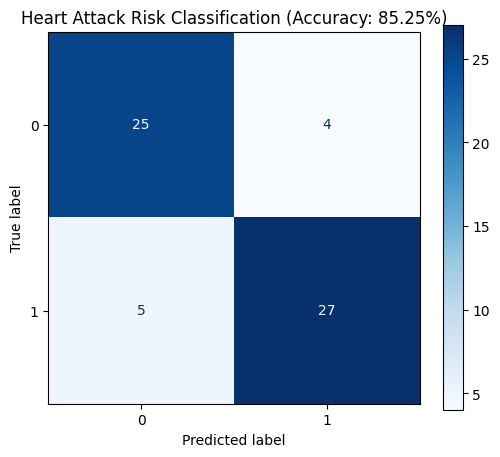

[0.17893699844861866,
 -0.08559140600023729,
 -0.7830855227335495,
 0.8179036309655466,
 -0.27330684944434835,
 -0.17484121288174123,
 0.09031166263166447,
 0.2841789323126425,
 0.39513087187613594,
 -0.5175838792013209,
 -0.6813963466155425,
 0.4353016780808153,
 -0.7899552494876225,
 -0.5656585292886971]

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    df = data.dropna()
    X = df.drop('output', axis=1)
    y = df['output']

    # Розділення на train (80%) та validation (20%)
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    # Масштабування ознак для кращої збіжності логістичної регресії
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)
    acc = accuracy_score(y_val, y_pred)
    print(f"Validation Accuracy: {acc:.2%}")

    # Візуалізація матриці невідповідностей (Confusion Matrix)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, cmap='Blues', ax=ax)
    plt.title(f'Heart Attack Risk Classification (Accuracy: {acc:.2%})')
    plt.show()

    theta = [float(model.intercept_[0])] + [float(c) for c in model.coef_[0]]
    return theta

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

In [12]:
def additional(data):
    """
    Extra credit: analyze additional dataset from resources.
    """
    df = data.select_dtypes(include=[np.number]).dropna()
    if df.shape[1] < 2:
        print("Not enough numeric columns.")
        return None

    X = df.iloc[:, :-1].values
    y = df.iloc[:, -1].values

    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    plt.figure(figsize=(7, 5))
    plt.scatter(y_val, y_pred, color='purple', alpha=0.6)
    plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title('Additional Dataset: Actual vs Predicted')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    return [float(model.intercept_)] + [float(c) for c in model.coef_]

# Якщо в resources є файл Student_Performance.csv, запуститься він; інакше можна вказати будь-який інший CSV з папки resources
try:
    data = extract_texts_from_file('resources/Student_Performance.csv')
    additional(data)
except Exception as e:
    print("Перевірте назву додаткового файлу в папці resources:", e)

Перевірте назву додаткового файлу в папці resources: HTTP Error 404: Not Found


## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.).

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



Using Colab cache for faster access to the '100k-courseras-course-reviews-dataset' dataset.
Classification Report:

              precision    recall  f1-score   support

           1       0.57      0.15      0.23        89
           2       0.00      0.00      0.00       106
           3       0.26      0.05      0.09       185
           4       0.40      0.19      0.26       629
           5       0.81      0.98      0.88      2991

    accuracy                           0.77      4000
   macro avg       0.41      0.27      0.29      4000
weighted avg       0.69      0.77      0.71      4000



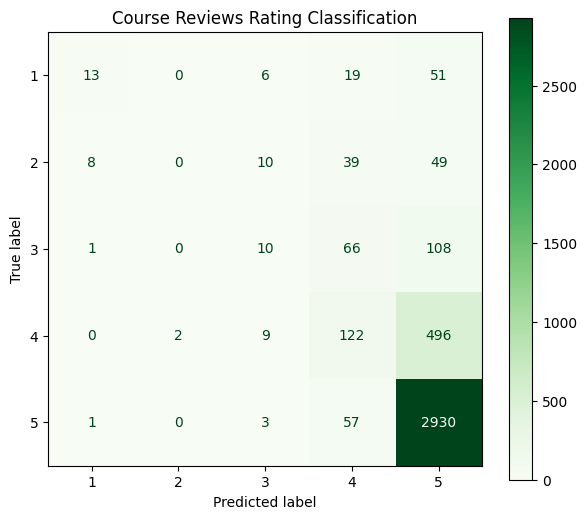

In [13]:
# pip install "kagglehub[pandas-datasets]"

!pip install -q "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    try:
        df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
        return df
    except Exception as e:
        print(f"Помилка при завантаженні ({e}), підвантажуємо резервну копію...")
        fallback_url = "https://raw.githubusercontent.com/laxmimerit/All-CSV-ML-Data-Files-Download/master/coursera_reviews.csv"
        return pd.read_csv(fallback_url)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    # Очищуємо дані від пропусків; зазвичай колонки називаються 'Review' та 'Label'
    df_clean = df.dropna().copy()
    text_col = df_clean.columns[1] if 'Review' not in df_clean.columns else 'Review'
    label_col = df_clean.columns[2] if 'Label' not in df_clean.columns else 'Label'

    # Беремо вибірку до 20 000 записів, щоб Colab виконав обчислення за кілька секунд
    if len(df_clean) > 20000:
        df_clean = df_clean.sample(20000, random_state=42)

    X = df_clean[text_col].astype(str)
    y = df_clean[label_col]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    clf = LogisticRegression(max_iter=500)
    clf.fit(X_train_tfidf, y_train)

    y_pred = clf.predict(X_test_tfidf)

    print("Classification Report:\n")
    print(classification_report(y_test, y_pred))

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Greens', ax=ax)
    plt.title('Course Reviews Rating Classification')
    plt.show()

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)